# 05 — Fairness Audit

## What can and cannot be claimed

These logs contain **no protected demographic attributes** — no age, gender,
ethnicity or income. A conventional demographic fairness audit is therefore
**not possible on this data, and is not claimed here**. Saying so plainly is
part of the contribution: a good deal of published "game fairness" work quietly
substitutes proxies without flagging it.

Two defensible substitutes are used instead:

1. **Contextual attributes that genuinely exist** — `platform` (iOS vs Android)
   and `device_family`. Not protected characteristics, but they correlate with
   device cost and so act as a coarse, openly acknowledged proxy for economic
   access.

2. **Behavioural segments** — engagement, spend and skill tiers. A model that is
   accurate for core players but unreliable for casual ones will systematically
   misdirect retention budget. That is an equity problem in the operational
   sense even with no protected attribute involved.

**Why one shared threshold.** All subgroups are scored at the *same* decision
threshold. Per-group thresholds would paper over exactly the disparity being
measured.

In [1]:
import os
import sys
from pathlib import Path

candidates = (
    [Path(os.environ["CHURN_PROJECT_ROOT"])] if "CHURN_PROJECT_ROOT" in os.environ else
    [Path.cwd() / ".pipeline", Path.cwd(), Path.cwd().parent / ".pipeline", Path.cwd().parent]
)
ROOT = next((candidate.resolve() for candidate in candidates
             if (candidate / "src" / "config.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run 00_setup.ipynb first or point CHURN_PROJECT_ROOT at the pipeline checkout.")
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
print("Pipeline modules are available.")

Pipeline modules are available.


In [2]:
from IPython.display import Image
from src import config, labeling, features, modeling, fairness, visualisation

GAME = "game1"
OP, CP = config.OBSERVATION_PERIOD_DAYS, config.CHURN_PREDICTION_PERIOD_DAYS

events = pd.read_parquet(config.INTERIM_DIR / f"{GAME}_events.parquet")
cohort = labeling.build_cohort(events, OP, CP)
feats = features.prune_features(features.build_features(events, cohort, OP))

results, artefacts = modeling.train_all(feats, GAME, do_cv=False)
split, best = artefacts["split"], artefacts["best"]
proba = artefacts["curves"][best]["proba"]
threshold = float(results.loc[results.model == best, "best_threshold"].iat[0])
print(f"auditing {best} at shared threshold {threshold:.4f}")

  cohort: 25,956 players -> 25,422 after left guard -> 25,121 after right guard -> 25,121 with OP activity | churn rate 92.6%


  dropped 2 uninformative columns: std_gap_hours, activity_slope
  train 20,096 / test 5,025 | 29 features | churn rate train 92.6%


    logistic_regression    ROC-AUC 0.7736 | PR-AUC(retained) 0.3372 (base 0.0740) | balanced acc 0.5519 | 0.3s


    random_forest          ROC-AUC 0.7280 | PR-AUC(retained) 0.2946 (base 0.0740) | balanced acc 0.5712 | 5.2s


    xgboost                ROC-AUC 0.7459 | PR-AUC(retained) 0.3120 (base 0.0740) | balanced acc 0.5632 | 3.8s
  best model by ROC-AUC: logistic_regression
auditing logistic_regression at shared threshold 0.0306


## Subgroup definitions

In [3]:
test_ctx = feats.iloc[split.test_idx].reset_index(drop=True)
segmented = fairness.add_behavioural_segments(test_ctx)

for attr in ["platform", "device_family", "engagement_tier", "spend_tier", "skill_tier"]:
    if attr in segmented.columns:
        print(f"\n{attr}:")
        print(segmented[attr].value_counts().to_string())


platform:
platform
Android    5025

engagement_tier:
engagement_tier
light     1675
medium    1675
heavy     1675

skill_tier:
skill_tier
mid     1675
low     1675
high    1675


## Per-subgroup performance

`fnr` (false negative rate) is the operationally serious error: a churning
player the model failed to flag is a player nobody tried to save.

In [4]:
report, summary = fairness.run_audit(
    test_ctx, split.y_test.to_numpy(), proba, threshold, GAME)
report.round(4)

  fairness [engagement_tier]: AUC gap 0.250 (worst light 0.521 vs best heavy 0.771), FNR gap 0.012
  fairness [skill_tier]: AUC gap 0.054 (worst mid 0.736 vs best high 0.790), FNR gap 0.006


,attribute,group,n,churn_rate,roc_auc,pr_auc_retained,baseline_pr_retained,fnr,fpr,selection_rate
0,platform,Android,5025,0.9260,0.7736,0.3372,0.0740,0.0037,0.8925,0.9887
1,engagement_tier,heavy,1675,0.8460,0.7706,0.4301,0.1540,0.0120,0.8450,0.9660
2,engagement_tier,light,1675,0.9701,0.5206,0.0360,0.0299,0.0000,1.0000,1.0000
3,engagement_tier,medium,1675,0.9618,0.6165,0.1099,0.0382,0.0000,1.0000,1.0000
4,skill_tier,high,1675,0.8955,0.7901,0.4439,0.1045,0.0067,0.8343,0.9767
5,skill_tier,low,1675,0.9558,0.7401,0.2226,0.0442,0.0006,0.9595,0.9976
6,skill_tier,mid,1675,0.9266,0.7360,0.2563,0.0734,0.0039,0.9350,0.9916


## Disparity summary

In [5]:
summary.round(4)

,attribute,groups,auc_gap,worst_group,worst_auc,best_group,best_auc,fnr_gap,fpr_gap,selection_rate_gap
0,engagement_tier,3,0.2500,light,0.5206,heavy,0.7706,0.012,0.1550,0.0340
1,skill_tier,3,0.0541,mid,0.7360,high,0.7901,0.006,0.1252,0.0209


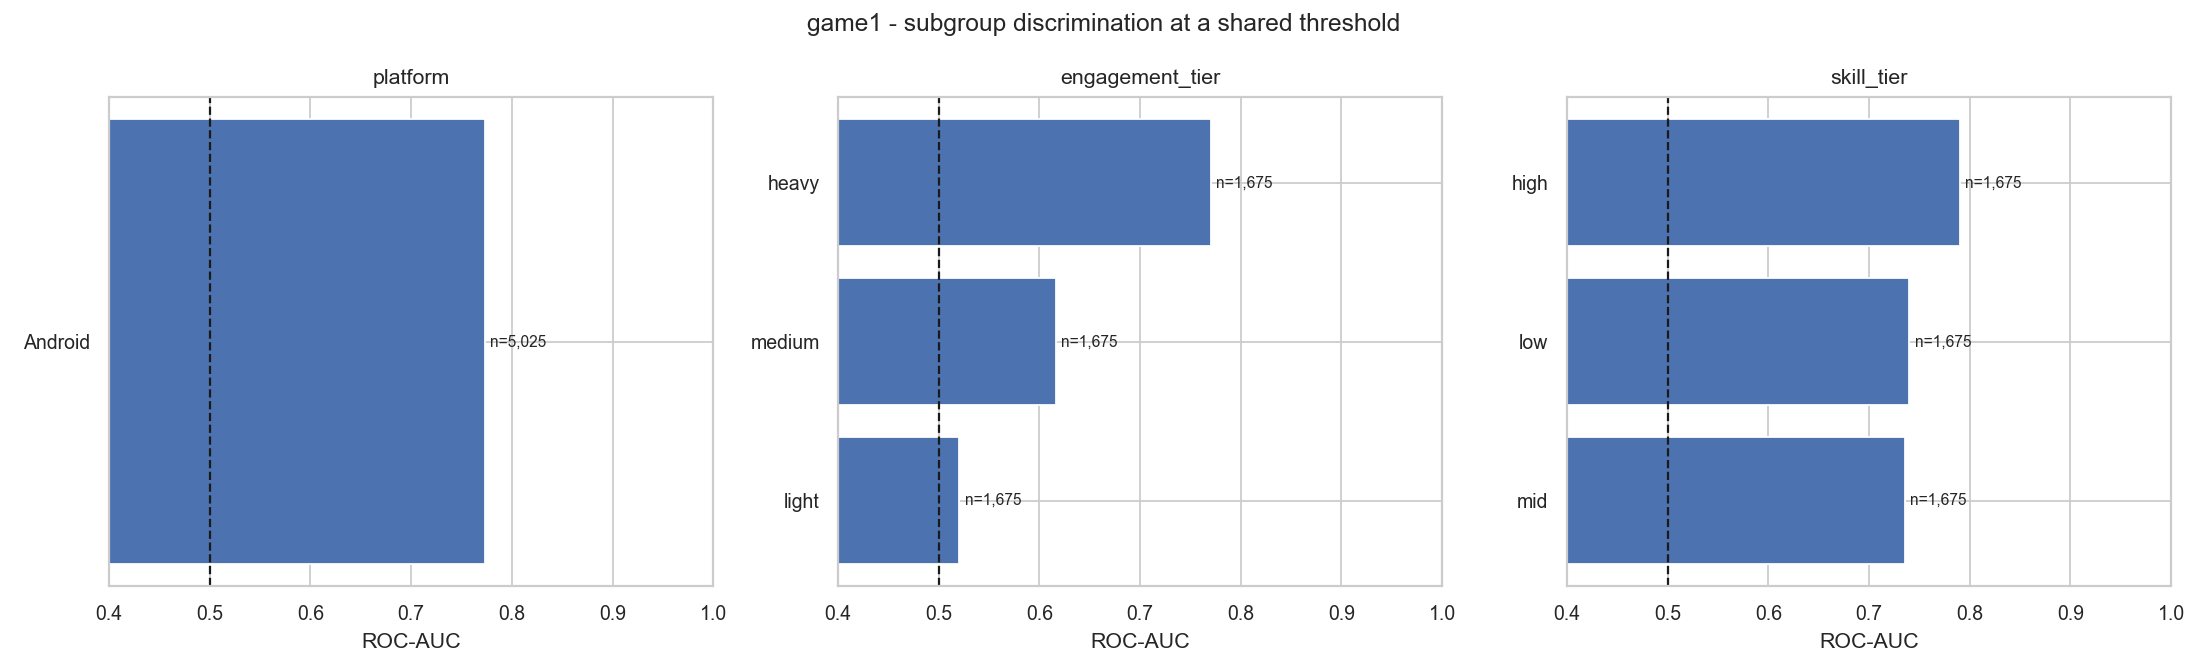

In [6]:
visualisation.plot_fairness(report, GAME)
Image(str(config.FIGURE_DIR / f"{GAME}_fairness.png"))

## Interpreting a large engagement-tier gap

A large AUC gap across engagement tiers is the expected — and most important —
finding. The model has abundant signal for players who generated a lot of
behaviour and very little for players who played once or twice.

This produces a **feedback loop** of exactly the kind that motivates the
research question: the retention system works best for players who were already
engaged, so retention spend flows toward them, while the casual majority — the
players most at risk and cheapest to save — are served by a model that is barely
better than a coin flip. Left unexamined, the system amplifies an existing
engagement gradient rather than correcting it.

Mitigations worth discussing in the report:

- separate models (or a cold-start model) for low-activity players
- richer early-signal features: time-to-first-action, tutorial completion, first-session drop-off point
- reporting performance **per segment** as a release gate, not just in aggregate
- accepting lower precision for casual players in exchange for higher recall,
  since the cost of a wasted incentive is far below the value of a saved player

In [7]:
if not summary.empty:
    worst = summary.iloc[0]
    print(f"Largest disparity: {worst.attribute}")
    print(f"  worst group : {worst.worst_group} (AUC {worst.worst_auc:.3f})")
    print(f"  best group  : {worst.best_group} (AUC {worst.best_auc:.3f})")
    print(f"  AUC gap     : {worst.auc_gap:.3f}")
    print(f"  FNR gap     : {worst.fnr_gap:.3f}")
    print(f"  selection rate gap: {worst.selection_rate_gap:.3f}")

Largest disparity: engagement_tier
  worst group : light (AUC 0.521)
  best group  : heavy (AUC 0.771)
  AUC gap     : 0.250
  FNR gap     : 0.012
  selection rate gap: 0.034
